In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'jax', 'jaxlib', 'flax', 'optax', 'orbax-checkpoint', 'tensorflow', 'protobuf', 'ml-dtypes']
imports = {'pillow': 'PIL', 'orbax-checkpoint': 'orbax', 'protobuf': 'google.protobuf', 'ml-dtypes': 'ml_dtypes'}
pinned = {'jax': ('0.12.0.1', 'jax==0.12.0.1', 'jax[cuda12]==0.12.0.1', 'exact'), 'jaxlib': ('0.12.0.1', 'jaxlib==0.12.0.1', 'jaxlib==0.12.0.1', 'exact'), 'flax': ('0.12.12', 'flax==0.12.12', 'flax==0.12.12', 'exact'), 'optax': ('0.2.8', 'optax==0.2.8', 'optax==0.2.8', 'exact'), 'orbax-checkpoint': ('0.12.0', 'orbax-checkpoint==0.12.0', 'orbax-checkpoint==0.12.0', 'exact')}
fallbacks = {'tensorflow': 'tensorflow==2.21.0', 'protobuf': 'protobuf==7.34.1', 'ml-dtypes': 'ml-dtypes==0.5.4'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        if requirement is None:  # a GPU-only package on a CPU runtime
            continue
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, cpu_requirement, _, match) in pinned.items():
    if not gpu and cpu_requirement is None:
        continue
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "46d487bb9b699b97c7c5fc5edd866e4d2ad7919b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/46d487bb9b699b97c7c5fc5edd866e4d2ad7919b/d2l"
for name in ('__init__.py', 'jax.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Recurrent Neural Networks

The count-based language models of that section predict each
token from a short window of immediate predecessors. A trigram model conditions
only on the two preceding tokens; anything earlier in the document has zero
influence on its prediction. Simply widening the window quickly hits a wall: a
count table spanning 20 BPE tokens would have to track $1024^{20} \approx
10^{60}$ contexts, and even a neural network reading a fixed window of $m$
concatenated token embeddings [@Bengio.Ducharme.Vincent.ea.2003] remains
blind to any token $m + 1$ steps back while growing linearly in parameter count
with $m$.

In that section, we introduced a fundamentally different approach: a
*latent* autoregressive model that compresses the entire history into a
fixed-size *hidden state* vector $\mathbf{h}_{t-1}$ and predicts the next token
from that summary,

$$P(x_t \mid x_{<t}) \approx P(x_t \mid \mathbf{h}_{t-1}), \qquad \mathbf{h}_t = g(\mathbf{h}_{t-1}, x_t).$$

Under this recurrence, the computational cost per step stays constant no matter
how long the prefix becomes. A *recurrent neural network* (RNN) parameterizes
the transition function $g$ with a neural network layer whose weights are
shared across all time steps [@elman1990finding]. (Note that a *hidden
state* carried across time steps differs from a feedforward *hidden layer*
sitting between input and output within a single step.) In this section, we
formulate the RNN language model, tally its parameters and compute, and
implement it both from scratch and with high-level framework layers on *The
Time Machine*.

In [1]:
import math
import numpy as np
import jax
from jax import numpy as jnp
from flax import nnx
import optax
from d2l import jax as d2l

In [2]:
import random

## Recurrent Neural Networks with Hidden States

An RNN is easiest to understand by starting from a single-hidden-layer MLP
(that section) and adding one recurrent connection. Given a minibatch of
$b$ examples with $d$ features each, $\mathbf{X} \in \mathbb{R}^{b \times d}$
(we use $b$ for batch size throughout this chapter because $n$ denotes $n$-gram
order), an ordinary hidden layer with activation function $\phi$ computes

$$\mathbf{H} = \phi(\mathbf{X} \mathbf{W}_{\textrm{xh}} + \mathbf{b}_\textrm{h}),$$

with $\mathbf{W}_{\textrm{xh}} \in \mathbb{R}^{d \times h}$ and
$\mathbf{b}_\textrm{h} \in \mathbb{R}^{1 \times h}$, followed by an output
projection $\mathbf{O} = \mathbf{H} \mathbf{W}_{\textrm{hq}} +
\mathbf{b}_\textrm{q}$ into $q$ logits.

Now suppose we receive a sequence of minibatch inputs
$\mathbf{X}_t \in \mathbb{R}^{b \times d}$ indexed by time step $t$. To let the
hidden representation remember earlier steps, we feed the previous hidden state
$\mathbf{H}_{t-1} \in \mathbb{R}^{b \times h}$ back into the layer via a
recurrent weight matrix
$\mathbf{W}_{\textrm{hh}} \in \mathbb{R}^{h \times h}$:

$$
\begin{aligned}
\mathbf{H}_t &= \phi(\mathbf{X}_t \mathbf{W}_{\textrm{xh}} + \mathbf{H}_{t-1} \mathbf{W}_{\textrm{hh}} + \mathbf{b}_\textrm{h}), \\
\mathbf{O}_t &= \mathbf{H}_t \mathbf{W}_{\textrm{hq}} + \mathbf{b}_\textrm{q}.
\end{aligned}
$$

Because the same five parameter tensors ($\mathbf{W}_{\textrm{xh}}$,
$\mathbf{W}_{\textrm{hh}}$, $\mathbf{b}_\textrm{h}$ in the recurrent layer and
$\mathbf{W}_{\textrm{hq}}$, $\mathbf{b}_\textrm{q}$ in the output layer) are
reused at every step (starting from $\mathbf{H}_0 = \mathbf{0}$), the parameter
count is completely independent of sequence length (the figure). Viewed
in unrolled form, an RNN running over $T$ steps is a $T$-layer feedforward
network whose layers all share the same weights.

![An RNN with a hidden state, unrolled across three adjacent time steps. The same weights are reused at every step.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-rnn-unfolded.svg)

Notice that the two matrix products in the equation equal a single
product of the horizontally concatenated inputs with the vertically stacked
weights:

$$[\mathbf{X}_t, \mathbf{H}_{t-1}] \begin{bmatrix} \mathbf{W}_{\textrm{xh}} \\ \mathbf{W}_{\textrm{hh}} \end{bmatrix} = \mathbf{X}_t \mathbf{W}_{\textrm{xh}} + \mathbf{H}_{t-1} \mathbf{W}_{\textrm{hh}}.$$

Libraries nevertheless keep the two products separate because during training
all inputs $\mathbf{X}_1, \ldots, \mathbf{X}_T$ are known up front, allowing
$\mathbf{X}_t \mathbf{W}_{\textrm{xh}}$ across all $T$ steps to be batched
outside the sequential time loop (exercise 1).

Furthermore, a recurrent state can solve tasks that are impossible for *any*
fixed-window model, such as reporting at every step whether the running count
of ones in a bit stream is even or odd (parity): flipping a bit older than any
fixed window $m$ reverses the true parity while leaving the last $m$ bits
unchanged, whereas a two-unit recurrent state tracks parity over arbitrary
lengths.

### Constant Memory per Step

Because computing $\mathbf{H}_t$ requires only $\mathbf{H}_{t-1}$ and
$\mathbf{X}_t$, both memory and computation per step remain constant regardless
of sequence length: with $h = 128$ `float32` hidden units, the state of a
sequence occupies just 512 bytes whether the model has read ten tokens or a
million. That constant footprint is also an inherent *lossy* bottleneck—every
detail remembered from the prefix must pass through those 512 bytes, unlike
*attention* (that section), which retains representations of every
past token at a cost that grows with sequence length.

### RNN Language Models and Teacher Forcing

An RNN language model consumes one token id per step and predicts a
distribution over the next token across all $q = |\mathcal{V}|$ vocabulary
entries (the figure). At step $t$, the $b$ token ids in the
minibatch look up their corresponding rows in a learned embedding table
$\mathbf{E} \in \mathbb{R}^{|\mathcal{V}| \times d}$ to form
$\mathbf{X}_t \in \mathbb{R}^{b \times d}$ (mathematically identical to
multiplying a $b \times |\mathcal{V}|$ one-hot matrix by $\mathbf{E}$, without
materializing or multiplying by zeros). The recurrent layer updates
$\mathbf{H}_t$, and $\textrm{softmax}(\mathbf{O}_t)$ defines
$P(x_{t+1} \mid x_{\leq t})$ in the chain-rule factorization
$P(x_1, \ldots, x_T) = \prod_{t=1}^T P(x_t \mid x_{<t})$
(that section).

![An RNN language model trained by teacher forcing over BPE tokens of *The Time Machine*. The target sequence is the input shifted forward by one token, so each step is trained to predict the next token.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-rnn-lm-shift.svg)

Where do the parameters and FLOPs sit? For our BPE vocabulary of
$|\mathcal{V}| = 1{,}027$ ids (1,024 BPE tokens plus three special tokens),
embedding width $d = 64$, and hidden size $h = 128$:

| part | shape | parameters |
|---|---|--:|
| embedding table $\mathbf{E}$ | $1{,}027 \times 64$ | 65,728 |
| input weight $\mathbf{W}_\textrm{xh}$ | $64 \times 128$ | 8,192 |
| recurrent weight $\mathbf{W}_\textrm{hh}$ | $128 \times 128$ | 16,384 |
| hidden bias $\mathbf{b}_\textrm{h}$ | $128$ | 128 |
| output weight $\mathbf{W}_\textrm{hq}$ | $128 \times 1{,}027$ | 131,456 |
| output bias $\mathbf{b}_\textrm{q}$ | $1{,}027$ | 1,027 |
| total | | 222,915 |

The recurrent layer accounts for just 24,704 parameters (11% of the model) and
$24{,}576$ multiply-adds per token, whereas the vocabulary-sized embedding and
output layers hold 89% of the parameters and the output projection alone costs
$128 \cdot 1{,}027 = 131{,}456$ multiply-adds.

During training, the input at every step is the *ground-truth* token from the
corpus regardless of what the model predicted at the previous step—a regime
known as *teacher forcing*. Because all ground-truth inputs in a window are
known up front, the entire window's cross-entropy loss (the logarithm of
perplexity) is evaluated in one forward pass. During generation, however, each
sampled or greedy token is fed back in as the next input, exposing the rollout
to its own errors just like our multistep sine-wave forecast in
that section.

## An RNN Language Model from Scratch

We now implement the three components of this language model (the recurrent
cell, the embedding lookup, and the output layer) from scratch.

### The Recurrent Cell

The `RNNScratch` class stores the parameters of the equation with
$\phi = \tanh$. We draw $\mathbf{W}_{\textrm{xh}}$ and
$\mathbf{W}_{\textrm{hh}}$ from $\mathcal{N}(0, \sigma^2)$ with $\sigma = 0.01$
and initialize $\mathbf{b}_\textrm{h}$ to zero. At this scale, the spectral
radius of $\mathbf{W}_{\textrm{hh}}$ is roughly $\sigma\sqrt{h} \approx 0.11$,
so an untrained cell decays its past state rapidly and leaves training to grow
recurrent weights where needed.

In [3]:
class RNNScratch(nnx.Module):
    """The RNN model implemented from scratch."""
    def __init__(self, num_inputs, num_hiddens, sigma=0.01, rngs=None):
        rngs = nnx.Rngs(random.getrandbits(32)) if rngs is None else rngs
        self.num_inputs, self.num_hiddens = num_inputs, num_hiddens
        self.sigma = sigma
        self.W_xh = nnx.Param(
            rngs.params.normal((num_inputs, num_hiddens)) * sigma)
        self.W_hh = nnx.Param(
            rngs.params.normal((num_hiddens, num_hiddens)) * sigma)
        self.b_h = nnx.Param(jnp.zeros(num_hiddens))

The forward pass loops over the leading time axis of `inputs` of shape
(`num_steps`, `batch_size`, `num_inputs`), initializing the hidden state to
zeros when none is supplied and returning the list of all per-step hidden
states alongside the final state.

When the training step is compiled, the Python loop is unrolled into one
copy of the cell per time step, so the compilation time grows with the
number of steps. The concise implementation at the end of this section
uses `nnx.RNN`, which runs the cell under `jax.lax.scan` and compiles it
only once.

In [4]:
@d2l.add_to_class(RNNScratch)
def __call__(self, inputs, state=None):
    if state is None:
        # Initial state with shape: (batch_size, num_hiddens)
        state = jnp.zeros((inputs.shape[1], self.num_hiddens))
    outputs = []
    for X in inputs:  # Shape of inputs: (num_steps, batch_size, num_inputs)
        state = d2l.tanh(d2l.matmul(X, self.W_xh) +
                         d2l.matmul(state, self.W_hh) + self.b_h)
        outputs.append(state)
    return outputs, state

To verify the recurrent cell's dimensions, we first run `RNNScratch` forward on
a dummy minibatch `X` of shape `(num_steps, batch_size, num_inputs)`.

In [5]:
batch_size, num_inputs, num_hiddens, num_steps = 2, 16, 32, 100
rnn = RNNScratch(num_inputs, num_hiddens)
X = d2l.ones((num_steps, batch_size, num_inputs))
outputs, state = rnn(X)

We now define a `check_shape` helper (reused throughout later chapters) to
confirm that stacking `outputs` produces `(num_steps, batch_size, num_hiddens)`
and `state` has shape `(batch_size, num_hiddens)`.

In [6]:
def check_shape(a, shape):
    """Check the shape of a tensor."""
    assert a.shape == shape, \
            f'tensor\'s shape {a.shape} != expected shape {shape}'

check_shape(d2l.stack(outputs, 0), (num_steps, batch_size, num_hiddens))
check_shape(state, (batch_size, num_hiddens))

### The Embedding and Output Layers

`RNNLMScratch` wraps a recurrent cell `rnn` with an embedding table `E` and an
output projection (`W_hq`, `b_q`), plus optional dropout rates on the
embeddings and hidden states. Embedding rows are initialized from
$\mathcal{N}(0, 1)$ (matching unit-scale one-hot inputs) while output weights
use scale $\sigma = 0.01$ with zero bias, so an untrained model produces
near-zero logits and an initial perplexity close to $|\mathcal{V}|$. Subclassing
`d2l.Classifier` provides mean cross-entropy loss, and overriding
`validation_step` records that loss directly so its exponential gives
validation perplexity.

In [7]:
class RNNLMScratch(d2l.Classifier):
    """The RNN-based language model implemented from scratch."""
    def __init__(self, rnn, vocab_size, lr=0.01, dropout=0, emb_dropout=0,
                 rngs=None):
        super().__init__()
        self.save_hyperparameters(ignore=['rnn', 'rngs'])
        self.rnn = rnn
        rngs = nnx.Rngs(random.getrandbits(32)) if rngs is None else rngs
        sigma = getattr(rnn, 'sigma', 0.01)  # Scale of the output weights
        self.E = nnx.Param(rngs.params.normal((vocab_size, rnn.num_inputs)))
        self.W_hq = nnx.Param(rngs.params.normal(
            (rnn.num_hiddens, vocab_size)) * sigma)
        self.b_q = nnx.Param(jnp.zeros(vocab_size))
        self.drop = nnx.Dropout(dropout, rngs=rngs)
        self.emb_drop = nnx.Dropout(emb_dropout, rngs=rngs)

    def validation_step(self, batch):
        return self.loss(self(*batch[:-1]), batch[-1])

Because the data loader yields minibatches of shape (`batch_size`,
`num_steps`), `embedding` transposes the token ids before indexing `E`,
returning a (`num_steps`, `batch_size`, `num_inputs`) tensor whose leading axis
is time.

In [8]:
@d2l.add_to_class(RNNLMScratch)
def embedding(self, X):
    # Output shape: (num_steps, batch_size, num_inputs)
    return self.E[X.T]

`output_layer` stacks the per-step states into shape (`batch_size`,
`num_steps`, `num_hiddens`) and applies the shared output projection in a
single batched matrix product, while `forward` chains embedding lookup,
dropout, the recurrent cell, and the output projection.

In [9]:
@d2l.add_to_class(RNNLMScratch)
def output_layer(self, rnn_outputs):
    # A list of per-step states, or a tensor whose first axis is time
    H = d2l.stack(list(rnn_outputs), 1)  # (batch_size, num_steps, num_hiddens)
    return d2l.matmul(H, self.W_hq) + self.b_q

@d2l.add_to_class(RNNLMScratch)
def forward(self, X, state=None):
    embs = self.emb_drop(self.embedding(X))
    rnn_outputs, _ = self.rnn(embs, state)
    H = d2l.stack(list(rnn_outputs), 0)  # (num_steps, batch_size, num_hiddens)
    return self.output_layer(self.drop(H))

Passing a dummy minibatch of token indices of shape `(batch_size, num_steps)`
through `RNNLMScratch` confirms that the returned logits tensor `outputs` has
shape `(batch_size, num_steps, vocab_size)`.

In [10]:
model = RNNLMScratch(rnn, vocab_size=1024)
outputs = model(d2l.ones((batch_size, num_steps), dtype=d2l.int32))
check_shape(outputs, (batch_size, num_steps, 1024))

## Gradient Clipping

Because an unrolled RNN applies the same transition Jacobian across $T$ steps,
gradients can shrink or grow exponentially with $T$ (that section). A
sudden gradient spike moves the parameters by Euclidean distance
$\eta\|\mathbf{g}\|$, overshooting the local region where the first-order
Taylor approximation holds and undoing dozens of updates in a single step.
Rather than shrinking $\eta$ across the board, *gradient clipping* caps the
global gradient norm (computed jointly over all model parameters) at a
threshold $\theta$ by projecting $\mathbf{g}$ onto the ball of radius $\theta$:

$$\mathbf{g} \leftarrow \min\left(1, \frac{\theta}{\|\mathbf{g}\|}\right) \mathbf{g}.$$

A gradient longer than $\theta$ is scaled back to length $\theta$ without
changing its direction, and a shorter one is left alone
(the figure).

![Gradient clipping as a projection onto the ball of radius $\theta$. The long gradient $\mathbf{g}$ is rescaled to length $\theta$ along its own direction, whereas the gradient $\mathbf{g}'$ inside the ball is left unchanged.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-rnn-grad-clipping.svg)

Whenever `gradient_clip_val` is positive, `d2l.Trainer` (that section)
applies the equation right after backpropagation and before the
optimizer step.

The JAX trainer updates the parameters with an optax transformation inside
its compiled training step, so the clipping goes there too:
`prepare_optimizer` turns `clip_gradients` into an optax transformation and
chains it in front of the model's optimizer.

In [11]:
def clip_gradients(grad_clip_val, grads):
    """Rescale the gradients to global norm at most grad_clip_val."""
    grad_leaves, _ = jax.tree_util.tree_flatten(grads)
    norm = jnp.sqrt(sum(jnp.vdot(x, x) for x in grad_leaves))
    clip = lambda grad: jnp.where(norm < grad_clip_val,
                                  grad, grad * (grad_clip_val / norm))
    return jax.tree_util.tree_map(clip, grads)

@d2l.add_to_class(d2l.Trainer)
def prepare_optimizer(self, model):
    val = self.gradient_clip_val
    key = (jax.tree.structure(model), type(model).configure_optimizers, val)
    if key not in d2l.optimizer_cache:
        tx = model.configure_optimizers()
        if val > 0:  # The closure holds only val, not the trainer
            clip = lambda grads, params: clip_gradients(val, grads)
            tx = optax.chain(optax.stateless(clip), tx)
        d2l.optimizer_cache.clear()
        d2l.optimizer_cache[key] = tx
    self.optim = nnx.Optimizer(model, d2l.optimizer_cache[key],
                               wrt=nnx.Param)

## Training and Evaluation

`d2l.TimeMachine` (that section) encodes the 65,741 BPE tokens
of the novella and yields minibatches of $T = 32$ overlapping windows—50,000
for training and 5,000 for validation, separated by a 32-window gap so no
validation token appears as a training target. Because each window starts from
$\mathbf{H}_0 = \mathbf{0}$, backpropagation is *truncated* to 32 steps
(that section).

In [12]:
data = d2l.TimeMachine(batch_size=1024, num_steps=32)

### A Plain Model and the Role of Clipping

We first instantiate our 222,915-parameter baseline model ($d = 64$, $h = 128$,
no dropout) with SGD learning rate $\eta = 4$.

In [13]:
rnn = RNNScratch(num_inputs=64, num_hiddens=128)
model = RNNLMScratch(rnn, vocab_size=len(data.vocab), lr=4)

Before training begins, we snapshot a NumPy copy of the random initial
embedding matrix `model.E` in `E_init` so we can measure how far SGD moves it.

In [14]:
E_init = d2l.numpy(model.E[...]).copy()

We next evaluate the untrained model's initial validation perplexity `ppl_init`
and then train `model` for 10 epochs with gradient clipping at
`gradient_clip_val=1`.

initial validation perplexity 1027


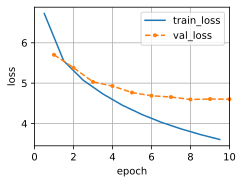

In [15]:
trainer = d2l.Trainer(max_epochs=10, gradient_clip_val=1, num_gpus=1)
ppl_init = math.exp(trainer.evaluate(model, data)['loss'])
print(f'initial validation perplexity {ppl_init:.0f}')
trainer.fit(model, data)

Exponentiating the final validation cross-entropy loss
`trainer.history['val_loss'][-1]` gives the trained baseline's validation
perplexity `ppl_plain`.

In [16]:
ppl_plain = math.exp(trainer.history['val_loss'][-1])
print(f'validation perplexity {ppl_plain:.1f}')

validation perplexity 99.8


Initial validation perplexity sits near $|\mathcal{V}| = 1{,}027$, and after
ten epochs the clipped model reaches a validation perplexity of about 85 to
100, even though its loss often jumps well above the starting value during the
first epoch (while training perplexity drops below half that value as the
222,915 parameters begin overfitting the 50,000 training tokens).

To see why gradient clipping is essential at $\eta = 4$, we define a helper
`unclipped_model()` that constructs a fresh baseline instance with the exact
same architecture and learning rate.

In [17]:
def unclipped_model():
    return RNNLMScratch(RNNScratch(num_inputs=64, num_hiddens=128),
                        vocab_size=len(data.vocab), lr=4)

We now train three independent unseeded instances without gradient clipping,
recording each run's epoch-by-epoch validation perplexities in `ppl_runs` and
reporting its peak and final values.

In [18]:
ppl_runs = []
for run in range(3):  # Three unseeded runs, no clipping
    trainer_unclipped = d2l.Trainer(max_epochs=10, num_gpus=1)
    trainer_unclipped.board.display = False  # One plot for all runs below
    trainer_unclipped.fit(unclipped_model(), data)
    ppls = [math.exp(loss) for loss in trainer_unclipped.history['val_loss']]
    ppl_runs.append(ppls)
    print(f'run {run + 1}: highest {max(ppls):.3g}, final {ppls[-1]:.3g}')
finals = [ppls[-1] for ppls in ppl_runs]
print(f'{sum(f > 2 * ppl_plain for f in finals)} of 3 runs end above twice '
      f'the clipped {ppl_plain:.3g}; finals from {min(finals):.3g} to '
      f'{max(finals):.3g}')

run 1: highest 249, final 83.7


run 2: highest 3.29e+04, final 1.39e+03


run 3: highest 3.47e+07, final 3.47e+07
2 of 3 runs end above twice the clipped 99.8; finals from 83.7 to 3.47e+07


Plotting the three unclipped trajectories in `ppl_runs` against the clipped
baseline `ppl_clipped` on a logarithmic axis makes the instability
unmistakable.

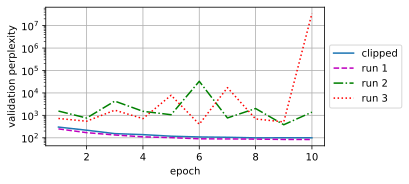

In [19]:
ppl_clipped = [math.exp(loss) for loss in trainer.history['val_loss']]
d2l.plot(list(range(1, 11)), [ppl_clipped] + ppl_runs, 'epoch',
         'validation perplexity', yscale='log',
         legend=['clipped', 'run 1', 'run 2', 'run 3'],
         legend_loc='outside', figsize=(5, 2.5))

Without clipping, gradient spikes send validation perplexity
jumping violently, sometimes far above the untrained baseline of 1,027, and most
runs finish at more than twice the clipped model's perplexity. Converting our
clipped validation perplexity to bits per byte (that section) divides
$\log_2 \textrm{ppl}$ by the average UTF-8 bytes per BPE token ($\approx 2.8$):

In [20]:
ids = d2l.numpy(data.X[data.num_train:data.num_train+data.num_val, 0]).tolist()
bytes_per_token = len(data.tokenizer.decode(ids).encode('utf-8')) / len(ids)
print(f'{bytes_per_token:.2f} bytes/token, '
      f'{math.log2(ppl_plain) / bytes_per_token:.2f} bits per byte')

2.78 bytes/token, 2.39 bits per byte


### Embeddings under SGD and a Wider Model with Dropout

Inspecting how far each row of $\mathbf{E}$ moved over the ten epochs of SGD
exposes a second bottleneck. We first extract the trained embedding table into
a NumPy array `E_final`.

In [21]:
E_final = d2l.numpy(model.E[...])

Computing the relative Euclidean displacement `change` between `E_final` and
`E_init` across all vocabulary rows reveals how little each token vector moved.

In [22]:
change = (((E_final - E_init) ** 2).sum(1) / (E_init ** 2).sum(1)) ** 0.5
print(f'mean change of an embedding row: {change.mean():.1%} of its length')

mean change of an embedding row: 4.2% of its length


Because row $i$ receives a gradient only from positions where token $i$ occurs,
and the loss averages over all $1{,}024 \times 32 = 32{,}768$ tokens in a
minibatch, rare or moderate-frequency tokens receive tiny gradients under a
uniform SGD learning rate, leaving $\mathbf{E}$ almost frozen. While adaptive
optimizers like Adam (that section) rescale per-coordinate step sizes to
move embeddings much further (explored in the exercises), we can also address
this directly within SGD: widening the embedding from $d = 64$ to $d = 512$
gives the densely updated input matrix $\mathbf{W}_{\textrm{xh}}$ a far richer
random feature basis, while adding dropout (0.1 on embeddings, 0.5 on hidden
states) curbs overfitting.

In [23]:
rnn = RNNScratch(num_inputs=512, num_hiddens=128)
model = RNNLMScratch(rnn, vocab_size=len(data.vocab), lr=4, dropout=0.5,
                     emb_dropout=0.1)

We train this wider regularized model for 10 epochs using the same learning
rate `lr=4` and clipping threshold `gradient_clip_val=1`.

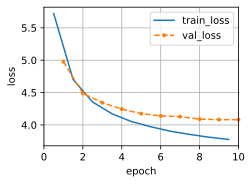

In [24]:
trainer = d2l.Trainer(max_epochs=10, gradient_clip_val=1, num_gpus=1)
trainer.fit(model, data)

From the final validation loss we compute both the validation perplexity
`ppl_scratch` and the corresponding compression rate in bits per byte.

In [25]:
ppl_scratch = math.exp(trainer.history['val_loss'][-1])
print(f'validation perplexity {ppl_scratch:.1f}, '
      f'{math.log2(ppl_scratch) / bytes_per_token:.2f} bits per byte')

validation perplexity 59.2, 2.12 bits per byte


Validation perplexity drops from 85–100 down to around 60, cutting bits
per byte from 2.3–2.4 to roughly 2.1.

### Comparison with Kneser–Ney and Effective Context Horizon

How does 2.1 bits per byte compare against interpolated Kneser--Ney smoothing
(that section)? The $1.9$ bits per byte that the Kneser--Ney
trigram reached in that section cannot serve as the yardstick:
that number was measured on lowercased text stripped to letters and spaces,
whereas this section models the raw novella with its capitals, punctuation,
and line breaks. We therefore fit Kneser--Ney $n$-grams
($n = 2, 3, 4$) on the exact same 50,000 BPE training tokens and evaluate them
on `val[32:]`, where each token is scored as the final target of its 32-token
validation window.

In [26]:
first_tokens = d2l.numpy(data.X[:, 0]).tolist()  # First token of each window
train = first_tokens[:data.num_train]
val = first_tokens[data.num_train:data.num_train + data.num_val]
lp_kns = {n: d2l.kneser_ney(train, val, len(data.vocab), n)[32:]
          for n in (2, 3, 4)}
for n, lp in lp_kns.items():
    bits = -sum(lp) / len(lp) / math.log(2)
    print(f'KN {n}-gram: {bits / bytes_per_token:.2f} bits per byte')
lp_kn = lp_kns[3]

KN 2-gram: 2.24 bits per byte
KN 3-gram: 2.09 bits per byte
KN 4-gram: 2.08 bits per byte


To score our trained RNN on the exact same held-out tokens `val[32:]`, we
select the slice `[start:stop]` of validation windows whose final target covers
`val[32:]`.

In [27]:
start, stop = data.num_train, data.num_train + data.num_val - 32  # val[32:]

Running `model` in evaluation mode over `data.X[start:stop]` in batches of
1,024 windows collects the matrix `logp` of per-position target
log-probabilities across all 32 window steps.

In [28]:
model_eval = nnx.view(model, deterministic=True, raise_if_not_found=False)
X_val, Y_val = data.X[start:stop], data.Y[start:stop]
logp = d2l.numpy(jnp.concatenate([  # Log-probability of every target
    jnp.take_along_axis(jax.nn.log_softmax(model_eval(X_val[i:i + 1024])),
                        Y_val[i:i + 1024, :, None], -1)[..., 0]
    for i in range(0, len(X_val), 1024)]))

The RNN and the trigram arrive at nearly the same average. Do they also make
the same predictions? The last column of `logp` scores the same tokens
`val[32:]` as `lp_kn`, so we can compare the two models token by token. We
also score their equal mixture $0.5\, P_\textrm{RNN} + 0.5\, P_\textrm{KN}$,
the usual way of combining a neural language model with a count-based one
[@Mikolov.Kombrink.Burget.ea.2011].

In [ ]:
lp_rnn, lp_tri = logp[:, -1], np.array(lp_kn)
lp_mix = np.logaddexp(lp_rnn, lp_tri) + math.log(0.5)  # 0.5 P_RNN + 0.5 P_KN
for name, lp in [('RNN', lp_rnn), ('KN trigram', lp_tri), ('mixture', lp_mix)]:
    print(f'{name}: {-lp.mean() / math.log(2) / bytes_per_token:.2f} '
          'bits per byte')
print(f'RNN more confident on {np.mean(lp_rnn > lp_tri):.0%} of the tokens')

The two models tie on average, but not token by token. The RNN assigns the
higher probability on about half the tokens and the trigram on the other
half, and the mixture lands about 0.06 bits per byte below the trigram, ahead
of both of its members.

A mixture can gain only where its members disagree, so the two models have
learned partly different things about the text. That makes the tie more
puzzling, not less. Why does a recurrent network reading 32 tokens of history
land near the same $\approx 2.1$ bits per byte as a Kneser--Ney trigram that
looks back only two tokens? To see
how much context the trained RNN actually uses, we plot its average validation
bits per byte at each window position $1, \ldots, 32$ against the Kneser--Ney
trigram baseline.

bits per byte with 1, 2, 3, 4, 8, 32 tokens of context: [2.29, 2.14, 2.12, 2.11, 2.11, 2.11]


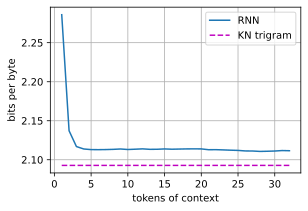

In [29]:
bits = -logp.mean(0) / math.log(2) / bytes_per_token  # One per position
kn_bits = -sum(lp_kn) / len(lp_kn) / math.log(2) / bytes_per_token
positions = np.arange(1, data.num_steps + 1)
d2l.plot(positions, [bits, [kn_bits] * data.num_steps],
         'tokens of context', 'bits per byte', legend=['RNN', 'KN trigram'],
         figsize=(4.5, 3))
print('bits per byte with 1, 2, 3, 4, 8, 32 tokens of context:',
      [round(float(bits[k - 1]), 2) for k in (1, 2, 3, 4, 8, 32)])

The diagnostic curve explains the tie. Almost all of the gain arrives with the
second token of context, which lowers the loss by about 0.15, from about 2.3
to about 2.14 bits per byte. The third token adds a hundredth or two, and from position 4
through 32 the curve is flat. Although the hidden state *can* depend on all 32
tokens in the forward pass, the trained model exploits only the last two or
three.

Why so few? One explanation is optimization: the gradient that would teach the
cell to use a distant token shrinks at every step on its way back, as we
measure in that section. The other is data: 50,000 training tokens may
hold little that can be learned about a token from those more than two or
three positions before it. The Kneser--Ney models printed above speak for the
second explanation. They are fit by counting, with no gradient that could
vanish, and they saturate at the same place: the trigram improves on the
bigram by 0.15 bits per byte, and the 4-gram improves on the trigram by only
0.01. Our experiment cannot tell the two explanations apart. A clean test
needs a model whose gradients survive over long lags, trained on the same
tokens, and that section builds such models.

## Text Generation

Once trained, our language model generates text autoregressively via `predict`:
it first warms up the hidden state on the user's prefix tokens, then generates
`num_tokens` continuation tokens by feeding each chosen token back in as the
next input (using greedy argmax when `temperature=0.0`, or sampling from the
temperature-scaled softmax otherwise; see that section).

In [30]:
@d2l.add_to_class(RNNLMScratch)
def predict(self, prefix, num_tokens, tok, device=None, temperature=0.0):
    model = nnx.view(self, deterministic=True, use_running_average=True,
                     raise_if_not_found=False)
    outputs, state = tok.encode(prefix), None
    for i in range(len(outputs) - 1):  # Warm up on the prefix
        X = d2l.tensor([[outputs[i]]])
        _, state = model.rnn(model.embedding(X), state)
    for _ in range(num_tokens):  # Generate num_tokens continuation tokens
        X = d2l.tensor([[outputs[-1]]])
        rnn_outputs, state = model.rnn(model.embedding(X), state)
        logits = model.output_layer(rnn_outputs)[0, 0]
        if temperature == 0:  # Greedy: the highest-scoring token
            token = logits.argmax()
        else:  # Sample from the softmax of logits / temperature
            token = jax.random.categorical(d2l.get_key(), logits / temperature)
        outputs.append(int(token))
    return tok.decode(outputs)

Let us test `model.predict` with greedy decoding (`temperature=0.0`) by
generating a 50-token continuation from the prompt `'The Time Traveller'`.

In [31]:
d2l.print_wrapped(repr(model.predict('The Time Traveller', 50,
                                     data.tokenizer)))

'The Time Traveller,\nand\nthere, I\nwas\nthe\nshall,\nthe\nshalled\nthe\nsh
    all,\nthe\nshalled\nthe\nshall,\nthe\nsha'


Because greedy decoding is deterministic, once the hidden state revisits a
recent phrase it cycles through that loop indefinitely—a failure mode we study
and fix in that section.

## Concise Implementation

Framework-supplied recurrent layers fuse the recurrent step and time loop into
optimized low-level kernels. The `RNN` module below matches the interface and
initialization of `RNNScratch`, and `RNNLM` subclasses `RNNLMScratch` by
swapping in built-in embedding and linear layers.

Flax NNX provides `SimpleCell` for a plain recurrent cell. It consumes one
time step and an explicit hidden state, and `nnx.RNN` scans it over the
input sequence. The cell's input projection carries the bias, and its
recurrent projection has none, so the cell has one bias vector, as
`RNNScratch` does.

In [32]:
class RNN(nnx.Module):
    """The RNN model implemented with high-level APIs."""
    def __init__(self, num_inputs, num_hiddens, sigma=0.01, rngs=None):
        rngs = nnx.Rngs(random.getrandbits(32)) if rngs is None else rngs
        self.num_inputs, self.num_hiddens = num_inputs, num_hiddens
        self.sigma = sigma
        normal = nnx.initializers.normal(sigma)
        cell = nnx.SimpleCell(num_inputs, num_hiddens, kernel_init=normal,
                              recurrent_kernel_init=normal, rngs=rngs)
        self.rnn = nnx.RNN(cell, time_major=True, return_carry=True,
                           rngs=rngs)

    def __call__(self, inputs, H=None):
        H, outputs = self.rnn(inputs, initial_carry=H)
        return outputs, H

In [33]:
class RNNLM(d2l.RNNLMScratch):
    """The RNN-based language model implemented with high-level APIs."""
    def __init__(self, rnn, vocab_size, lr=0.01, dropout=0, emb_dropout=0,
                 rngs=None):
        d2l.Classifier.__init__(self)
        self.save_hyperparameters(ignore=['rnn', 'rngs'])
        self.rnn = rnn
        rngs = nnx.Rngs(random.getrandbits(32)) if rngs is None else rngs
        sigma = getattr(rnn, 'sigma', 0.01)  # Scale of the output weights
        self.emb = nnx.Embed(vocab_size, rnn.num_inputs,
                             embedding_init=nnx.initializers.normal(1.0),
                             rngs=rngs)
        self.linear = nnx.Linear(
            rnn.num_hiddens, vocab_size,
            kernel_init=nnx.initializers.normal(sigma), rngs=rngs)
        self.drop = nnx.Dropout(dropout, rngs=rngs)
        self.emb_drop = nnx.Dropout(emb_dropout, rngs=rngs)

    def embedding(self, X):
        return self.emb(X.T)

    def output_layer(self, hiddens):
        return d2l.swapaxes(self.linear(hiddens), 0, 1)

To verify our high-level implementation, we instantiate `RNN` and `RNNLM` with
the same hyperparameters ($d = 512$, $h = 128$, and dropout).

In [34]:
rnn = RNN(num_inputs=512, num_hiddens=128)
model = RNNLM(rnn, vocab_size=len(data.vocab), lr=4, dropout=0.5,
              emb_dropout=0.1)

We now train `RNNLM` for 10 epochs with `gradient_clip_val=1`, running the
fused recurrent kernel at a fraction of the from-scratch wall-clock time.

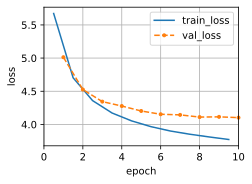

In [35]:
trainer = d2l.Trainer(max_epochs=10, gradient_clip_val=1, num_gpus=1)
trainer.fit(model, data)

Finally, we report the concise model's validation perplexity `ppl_concise`
alongside a 30-token greedy continuation from `'The Time Traveller'`.

In [36]:
ppl_concise = math.exp(trainer.history['val_loss'][-1])
pred = model.predict('The Time Traveller', 30, data.tokenizer)
d2l.print_wrapped(f'perplexity {ppl_concise:.1f}, {pred!r}')

perplexity 60.5, 'The Time Traveller. I felt assured the\nsharaced the\nday.
    I had seen. I had seen. I had'


## Summary

A recurrent neural network updates a fixed-size hidden state from the current
input and previous state using weights shared across all time steps, achieving
constant memory and compute per step at the cost of compressing history into a
lossy state vector. An RNN language model pairs an embedding table, a
$\tanh$ recurrent cell, and a vocabulary-sized output projection (where 89% of
our baseline's parameters reside), trained by teacher forcing to minimize
per-token cross-entropy. Global gradient clipping (the equation)
prevents exploding gradient spikes from derailing training at high learning
rates. On *The Time Machine*, a wider embedding with dropout brings the
SGD-trained RNN to $\approx 2.1$ bits per byte, tying an interpolated
Kneser--Ney trigram: the trained vanilla RNN effectively exploits only
the last two or three tokens of context. that section measures how far
its gradients reach.

## Exercises

1. **Separating the input product.** Let
   $\mathbf{X}_t \in \mathbb{R}^{b \times d}$ and
   $\mathbf{H}_{t-1} \in \mathbb{R}^{b \times h}$ be the input and
   the state in the equation.
    1. During training, the inputs $\mathbf{X}_1, \ldots, \mathbf{X}_T$
       of a window are all known before the first time step is computed.
       Which of the two products $\mathbf{X}_t \mathbf{W}_{\textrm{xh}}$
       and $\mathbf{H}_{t-1} \mathbf{W}_{\textrm{hh}}$ can be computed for
       all $T$ steps in a single matrix multiplication, and what are the
       shapes of its factors? Which product must stay inside the
       sequential loop over time steps, and why?
    1. Compare the work per step left inside the loop with the work per
       step of the concatenated form $[\mathbf{X}_t, \mathbf{H}_{t-1}]$.
       During generation, the input at step $t$ is the token generated at
       step $t-1$. Does the advantage of the separate form survive there?

1. **Exposure bias.** Teacher forcing (that section)
   conditions every training step on the true prefix, whereas generation
   conditions each step on the model's own earlier outputs. The resulting
   mismatch is called *exposure bias* [@Ranzato.Chopra.Auli.ea.2016].
    1. Suppose generation samples each token from the model's next-token
       distribution, and the model assigns probability $1 - \epsilon$ to
       the correct next token whenever its prefix is correct. What is the
       probability that $T$ generated tokens contain no error? Evaluate
       it for $\epsilon = 0.01$ and $T = 100$.
    1. *Scheduled sampling* [@Bengio.Vinyals.Jaitly.ea.2015] exposes
       the model to its own outputs during training: at each step, with
       some probability, the input is a token sampled from the model's
       prediction at the previous step instead of the true token. Which
       property of teacher forcing that
       that section relies on does this give up, and
       how does that change the computation of a training window?

1. **A window inside a recurrence.** The neural $n$-gram reads a fixed
   window of the last $m$ input embeddings. Take $\phi$ to be the identity
   and $\mathbf{b}_\textrm{h} = \mathbf{0}$ in the equation,
   and give the state $h = md$ units.
    1. Choose $\mathbf{W}_{\textrm{xh}}$ and $\mathbf{W}_{\textrm{hh}}$ so
       that, starting from $\mathbf{H}_0 = \mathbf{0}$, the state is the
       concatenation
       $\mathbf{H}_t = [\mathbf{X}_t, \mathbf{X}_{t-1}, \ldots, \mathbf{X}_{t-m+1}]$
       for every $t \geq m$.
    1. Show that $\mathbf{W}_{\textrm{hh}}^m = \mathbf{0}$, and explain why
       this means that no input older than $m$ steps affects
       $\mathbf{H}_t$.
    1. For $d = 256$ and $m = 20$, how many state units does this
       construction need? Explain what an RNN whose state has only 256
       units must do instead of storing the window.

1. [code] **Embedding lookup as a product.** Let
   $\mathbf{E} \in \mathbb{R}^{|\mathcal{V}| \times d}$ be an embedding
   table, and let $\mathbf{x}$ hold the token ids of a minibatch of $b$
   tokens.
    1. Compute the inputs once by selecting the rows of $\mathbf{E}$ that
       $\mathbf{x}$ indexes and once as the product of the
       $b \times |\mathcal{V}|$ one-hot matrix of $\mathbf{x}$ with
       $\mathbf{E}$, and check that the two agree. Time both for
       $|\mathcal{V}| \in \{10^3, 10^4, 10^5\}$ with $d = b = 256$, and
       state how the running time of each grows with $|\mathcal{V}|$.
    1. Differentiate the sum of all entries of the selected rows with
       respect to $\mathbf{E}$ by automatic differentiation. Which rows of
       the gradient are nonzero, and what does a row contain when its
       token occurs several times in the minibatch? For
       $|\mathcal{V}| = 10^4$ and $b = 256$ ids drawn uniformly at random,
       estimate the fraction of rows that receive a nonzero gradient.

1. **Parity beyond any window.** ● Let $x_1, x_2, \ldots$ be a sequence of
   bits, and let the desired output at step $t$ be the parity of
   $x_1 + \cdots + x_t$.
    1. Show that no model that reads only the last $m$ inputs can produce
       the correct output at every step of a sequence longer than $m$,
       whatever the finite $m$.
    1. Let $\phi$ be a threshold activation. Construct an RNN of the form
       the equation with two hidden units whose output
       equals the parity at every step, for any sequence length. Give
       the weights, and show that one hidden unit does not suffice.
    1. How many bits of information about $x_1, \ldots, x_t$ must the
       hidden state retain for the outputs at all later steps to be
       correct? Relate this to the description of the state as a lossy
       fixed-size summary in that section.

1. [code] **Gradient clipping ablation.** `d2l.Trainer` applies the
   projection the equation whenever `gradient_clip_val` is
   positive.
    1. Record the norm of the gradient before clipping at every update
       of the first epoch, and plot it. How often does clipping act, and
       when?
    1. Most unclipped runs of this section jumped at `lr=4`. Halve the
       learning rate until three unclipped runs in a row train without a
       jump in the validation perplexity. How does their validation
       perplexity after ten epochs compare with that of the clipped run at
       `lr=4`? What, then, does clipping make possible?
    1. Replace $\tanh$ by ReLU in `RNNScratch` and train again, with and
       without clipping. Is clipping still needed? Explain the difference
       from the $\tanh$ cell in terms of the range of the hidden state.

1. [code] **Usable history.** Every training window starts from a zero
   state, so the model is never trained to use more than `num_steps`
   tokens of context, and the loss by position showed that it uses far
   fewer. `predict`, by contrast, carries the state across the whole
   prefix and every generated token. Evaluate the trained model
   on 512 consecutive validation tokens in two ways: resetting the state
   to zero every 32 tokens as in training, and carrying the state across
   all 512 tokens. Compare the average cross-entropy of the two. Does the
   carried state help, hurt, or make no difference, and what does the
   answer say about the states the model reaches beyond its training
   horizon?

1. [code] **Adam.** Train the model with the wider embedding with the Adam
   optimizer of that section instead of SGD: subclass
   `RNNLMScratch`, override `configure_optimizers` to return Adam with
   learning rate 0.003, and keep clipping at 1.
    1. With `emb_dropout=0.2`, score the tokens `val[32:]` as in the
       comparison above, and compare its bits per byte with the SGD
       model, the Kneser–Ney trigram and 4-gram, and the mixture of the
       RNN and the trigram at $\lambda = 0.5$.
    1. Record the validation loss after every epoch, with
       `emb_dropout=0.1` and with 0.2. At which epoch is it lowest, and what
       happens after that?
    1. Measure again how far the embedding rows move during training. Why
       does Adam move them further than SGD does?

1. [code] **Vocabulary size and bits per byte.** ● Retrain the model with
   the wider embedding for `vocab_size` 512, 1,024, 2,048, and 4,096 in
   `d2l.TimeMachine`. The number of windows depends on the vocabulary size,
   so split by fraction: build each dataset once to read off
   `n = len(data.X)`, then build it again with `num_train=int(0.8 * n)` and
   `num_val=n - int(0.8 * n)`. (Setting `data.num_train` afterwards would
   skip the step that keeps validation tokens out of the training targets.)
   Every model then trains and validates on about the same stretch of text.
   Their per-token perplexities are not comparable, so compare them by bits
   per byte.
    1. Which vocabulary size gives the lowest bits per byte?
    1. How do the parameter counts of the embedding table and the output
       layer, and the length of the corpus in tokens, change with the
       vocabulary size? Which of these effects best explains the trend
       you measured?

1. [code] **Cross-book generalization.** ● Subclass `d2l.TimeMachine` and
   override `_download` to return the text of a different H. G. Wells
   novel, such as *The War of the Worlds* (Project Gutenberg ebook 36).
   Train the tokenizer and the model on it.
    1. Evaluate the model on held-out text of its own novel and on *The
       Time Machine*, encoding both with the new novel's tokenizer.
       Report perplexity and bits per byte for both.
    1. Write $s = \log_2(\textrm{ppl})$ for the per-token surprisal and
       $b$ for the bytes per token of an evaluated text, so that bits per
       byte is $s / b$. The ratio of bits per byte on *The Time Machine*
       (TM) to bits per byte on the held-out text of the new novel (own)
       factors as
       $$\frac{s_\textrm{TM}}{s_\textrm{own}} \cdot \frac{b_\textrm{own}}{b_\textrm{TM}}.$$
       The first factor reflects the model's predictions and the second
       the tokenizer's compression. Measure both factors. Which lies
       further from one?

[Discussions](https://d2l.discourse.group/t/18014)